# Payment and Order Pattern Analytics
**ST1519 Agile MLOps CA1 Part 2 - Individual | Eaint Chu Nay Chi | P2534974 | Task #63**

## 1. Analytical Objective
I investigate payment and order patterns in SP-buy's labelled transactions to help
Trust & Safety analysts decide where closer investigation may be useful. I answer:

1. Which payment methods have the highest fraud rates, taking transaction volumes into account?
2. Within each payment method, how do fraud rates differ across order-value ranges?
3. How do fraud rates differ between delivery and pickup orders across payment methods?

For each question, I explain the method, present a table and chart, interpret the
observed results, and connect the findings to an investigation decision. These are
retrospective analyses of labelled orders; a segment's observed rate does not establish
that an individual transaction is fraudulent.

**Data freshness:** running all cells retrieves the latest cleaned data from the shared
AWS RDS database. Saved outputs describe the retrieval timestamp displayed below, not
necessarily the current database state. The presentation update was checked using the
previously saved RDS snapshot; it does not claim another live database verification.

## 2. Definitions and Analytical Choices

| Choice | Approach and reason |
|---|---|
| Unit of analysis | One labelled order. I join `fraud_labels` and `orders` using both `country_code` and `order_id`, because an order ID can occur in different countries. |
| Fraud-rate denominator | Labelled orders in the same group. Orders without a label are counted separately, rather than assumed to be non-fraud. |
| Combining countries | Sum fraud counts and order counts before dividing. Averaging country percentages would give small and large countries equal weight. |
| Order-value ranges | SGD 0, `(0, 10]`, `(10, 25]`, `(25, 50]`, `(50, 100]`, and above SGD 100. The brief defines values in SGD. Fixed, interpretable boundaries allow comparisons across payment methods and executions. |
| Valid special categories | Keep zero-value orders, `no payment`, and the cleaned `unknown` payment category. Unknown means payment information was not recorded; it is not a named provider. |
| Support for highlighted findings | Highlight groups with at least 100 labelled orders; retain every observed group in the exported tables and charts. This reporting rule is not a significance test or blocking threshold. |
| Uncertainty | Show 95% Wilson intervals with rates and counts. Small samples and repeated customers limit interpretation. |
| Country composition | Export country-specific breakdowns because payment availability and transaction mixes differ across countries. Pooled comparisons do not isolate a causal payment or collection effect. |

**Core calculation:** `fraud rate (%) = fraud-labelled orders / labelled orders × 100`.
A high rate identifies concentration within a segment, while a high fraud count
identifies the scale of observed fraud. I consider both when interpreting the results.

## 3. Imports and Configuration
I reuse `src/analytics_payment_order_chu.py` for the SQL, calculations, figures and
exports, so the notebook and command-line analysis use the same implementation.

Connection settings come from the project's existing `DB_*` environment variables.
Start the notebook with the project `.venv` kernel after configuring those variables.
The following cell checks that the required settings exist without printing their values.

In [1]:
from pathlib import Path
import sys
import os
import pandas as pd
from IPython.display import display, Image, Markdown, Code

repo = Path.cwd()
if not (repo / "src").is_dir() and (repo.parent / "src").is_dir():
    repo = repo.parent
sys.path.insert(0, str(repo / "src"))
from analytics_payment_order_chu import (
    run_analysis, GROUP_QUERY, VALUE_BANDS, MIN_HIGHLIGHT_ORDERS
)

required = ["DB_HOST", "DB_USER", "DB_PASSWORD"]
missing = [name for name in required if not os.environ.get(name)]
if missing:
    raise RuntimeError(
        "Configure DB_* environment variables before launching the kernel: "
        + ", ".join(missing)
    )
pd.set_option("display.max_columns", 15)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## 4. Retrieve and Understand the RDS Data
### 4.1 How the records are joined and grouped
The SQL below is imported directly from the analysis module, so it shows the query
used by the implementation. It joins labels to orders on their composite identifiers,
assigns the SGD value band, and counts orders and fraud labels for each combination
of country, payment method, collection type and value band.

RDS performs the counting, and Python receives only aggregate rows. The three
question-specific functions then regroup this common result:

- `query_payment_methods()` compares payment methods.
- `query_order_values()` compares value bands within each method.
- `query_collection_types()` compares delivery and pickup within each method.

This is one shared SQL aggregate retrieval followed by three analytical queries in
Python. It avoids repeatedly downloading the full order-level dataset.

In [2]:
display(Code(GROUP_QUERY.strip(), language="sql"))

SELECT o.country_code, o.payment_method, o.collect_type, CASE WHEN o.order_value=0 THEN 'SGD 0'
    WHEN o.order_value<=10 THEN '(0, 10]' WHEN o.order_value<=25 THEN '(10, 25]'
    WHEN o.order_value<=50 THEN '(25, 50]' WHEN o.order_value<=100 THEN '(50, 100]'
    ELSE '> SGD 100' END AS value_band,
           COUNT(*) AS orders, SUM(l.is_fraud) AS frauds,
           MIN(o.order_date) AS first_order_date, MAX(o.order_date) AS last_order_date
    FROM fraud_labels l JOIN orders o ON o.country_code=l.country_code AND o.order_id=l.order_id
    GROUP BY o.country_code, o.payment_method, o.collect_type, value_band

### 4.2 Execute the analysis and inspect the population
`run_analysis()` retrieves fresh aggregates, applies the three analyses and saves
their tables, charts and summary in a new execution folder. It rejects invalid values,
unmatched labels and join/count inconsistencies before producing the results.

I inspect the retrieval time, order-date range, labelled population and unlabelled
count before interpreting the charts. The date range describes the available dataset;
it does not imply that these historical orders occurred near today's date.

In [3]:
result = run_analysis()
tables = result["tables"]
overview = result["overview"]
output_dir = Path(result["output_dir"])

display(pd.Series(overview, name="Data retrieval and execution overview"))

source                  team RDS business database; fraud_labels joine...
retrieved_at                             2026-11-28T16:22:34.779031+00:00
orders                                                             949969
frauds                                                             104433
all_orders                                                         949993
unlabelled_orders                                                      24
first_order_date                                               2022-11-12
last_order_date                                                2023-05-11
countries                                            [BD, MY, PH, PK, TH]
read_seconds                                                        24.14
run_id                                          20261128T162210Z_720332f9
duration_seconds                                                    25.41
value_bands_sgd         [SGD 0, (0, 10], (10, 25], (25, 50], (50, 100]...
highlight_min_orders                  

## 5. Population and Result Checks
Before comparing groups, I check that each question accounts for the same number
of labelled orders and fraud labels. Each main table partitions that population once.
These checks can detect missing or repeated groups, although matching totals alone
do not establish that every upstream record is correct.

In [4]:
question_tables = {
    "Q1: payment methods": "q1_payment_methods",
    "Q2: payment and value": "q2_payment_value",
    "Q3: payment and collection": "q3_payment_collection",
}
population_checks = pd.DataFrame([
    {"analysis": question,
     "labelled_orders": int(tables[name]["orders"].sum()),
     "fraud_labels": int(tables[name]["frauds"].sum())}
    for question, name in question_tables.items()
])
assert population_checks["labelled_orders"].eq(overview["orders"]).all()
assert population_checks["fraud_labels"].eq(overview["frauds"]).all()
assert overview["all_orders"] == overview["orders"] + overview["unlabelled_orders"]
display(population_checks)
overall_rate = 100 * overview["frauds"] / overview["orders"]
display(Markdown(
    f"The analyses cover **{overview['orders']:,} labelled orders**, including "
    f"**{overview['frauds']:,} fraud labels ({overall_rate:.2f}%)**. "
    f"The **{overview['unlabelled_orders']:,} unlabelled orders** are outside "
    "the fraud-rate denominator. All three analytical views reconcile."
))

,analysis,labelled_orders,fraud_labels
0,Q1: payment methods,949969,104433
1,Q2: payment and value,949969,104433
2,Q3: payment and collection,949969,104433


The analyses cover **949,969 labelled orders**, including **104,433 fraud labels (10.99%)**. The **24 unlabelled orders** are outside the fraud-rate denominator. All three analytical views reconcile.

## 6. Q1 - Payment-Method Fraud Rates and Transaction Volumes
**Question:** Which payment methods have the highest fraud rates, taking transaction
volumes into account?

### 6.1 Method and calculations
I sum labelled-order and fraud counts for each payment method across countries,
value bands and collection types. I calculate:

- **Fraud rate:** fraud count / labelled-order count × 100.
- **Share of observed fraud:** the method's fraud count / all fraud labels × 100.
- **Risk lift:** the method's fraud rate / the overall fraud rate.

A lift above 1 means the observed rate exceeds the overall baseline. A method can
have a high rate but few fraud cases, or a moderate rate and many fraud cases.
Both patterns may matter for different investigation priorities.

In [5]:
q1 = tables["q1_payment_methods"]
q1_columns = [
    "payment_method", "orders", "frauds", "fraud_rate_pct",
    "ci_low_pct", "ci_high_pct", "share_fraud_pct", "risk_lift"
]
display(q1[q1_columns])

,payment_method,orders,frauds,fraud_rate_pct,ci_low_pct,ci_high_pct,share_fraud_pct,risk_lift
0,jazzcash wallet,2509,1227,48.90,46.95,50.86,1.17,4.45
1,no payment,670,219,32.69,29.24,36.33,0.21,2.97
2,antfinancial bkash,17889,4648,25.98,25.35,26.63,4.45,2.36
3,generic creditcard,72325,14053,19.43,19.14,19.72,13.46,1.77
4,payment on delivery,312664,50274,16.08,15.95,16.21,48.14,1.46
5,balance,25937,4153,16.01,15.57,16.46,3.98,1.46
6,invoice,1965,305,15.52,13.99,17.19,0.29,1.41
7,antfinancial gcash,102660,8729,8.50,8.33,8.68,8.36,0.77
8,credit card,114247,9318,8.16,8.00,8.32,8.92,0.74
9,paypal,367,26,7.08,4.88,10.18,0.02,0.64


### 6.2 Visual comparison
The left panel compares observed fraud rates and their 95% Wilson intervals.
The right panel shows exact transaction counts on a logarithmic axis, allowing
small and large payment methods to remain visible together. Wider intervals
indicate greater sampling uncertainty under the binomial approximation.

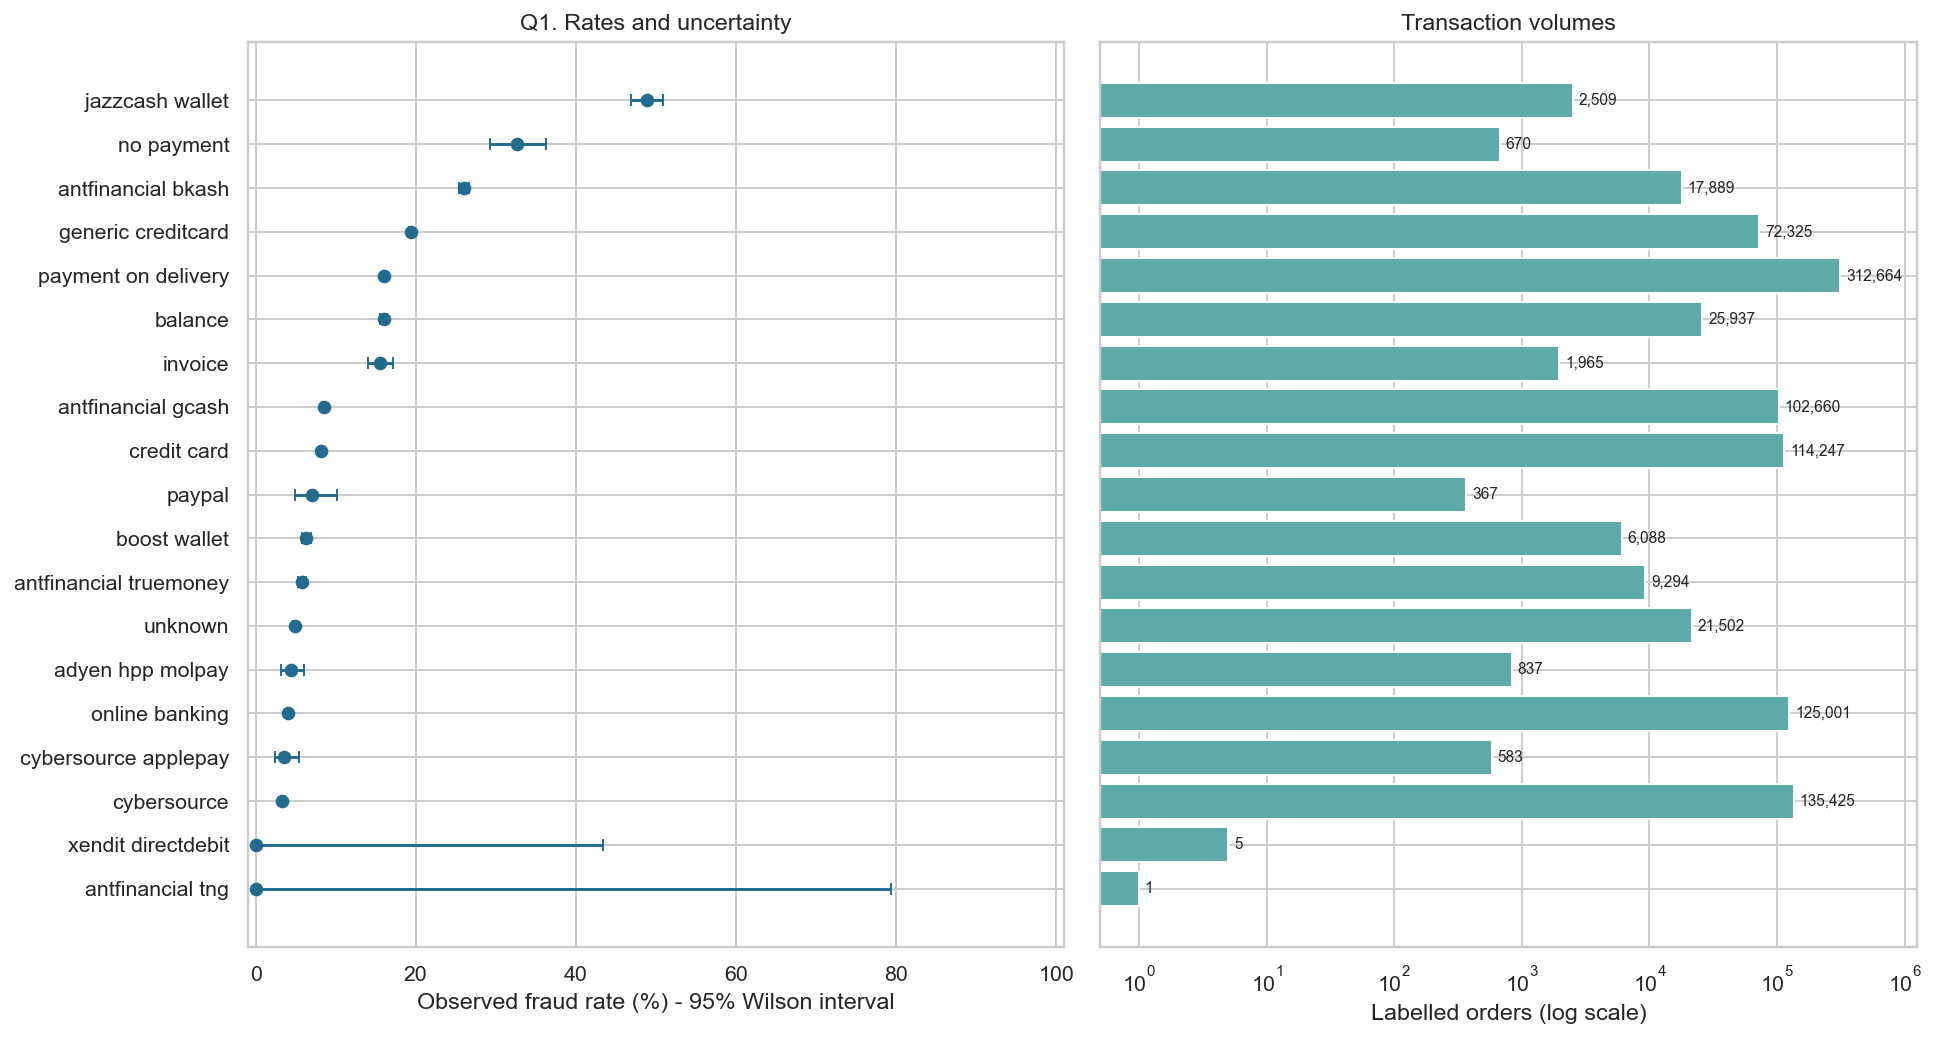

In [6]:
display(Image(filename=str(output_dir / "q1_payment_methods.png")))

### 6.3 Insights from the payment-method results
The following interpretation is generated from this execution's results. The
highest-rate example uses the minimum support rule; the largest fraud count
identifies a separate consideration for allocating investigation capacity.

In [7]:
q1_text = result["summary"].split("## Q1.", 1)[1].split("## Q2.", 1)[0]
q1_body = q1_text.split("\n", 1)[1].strip()
q1_insights, q1_decision = q1_body.split("Decision:", 1)
display(Markdown(q1_insights.strip()))

supported_q1 = q1[q1["highlight_support"]].sort_values(
    ["fraud_rate_pct", "orders", "payment_method"], ascending=[False, False, True]
)
if not supported_q1.empty:
    example = supported_q1.iloc[0]
    display(Markdown(
        f"**Calculation check — {example.payment_method}:** "
        f"{int(example.frauds):,} ÷ {int(example.orders):,} × 100 "
        f"= **{example.fraud_rate_pct:.2f}%**. The denominator includes only "
        "labelled orders using that payment method."
    ))
else:
    display(Markdown("No payment method meets the support rule for a highlighted rate comparison."))

Among methods with at least 100 labelled orders, **jazzcash wallet** has the highest observed fraud rate: 48.90% (1,227/2,509; 95% interval 46.95-50.86%).
**payment on delivery** contributes the most fraud-labelled orders: 50,274 (48.14% of observed fraud), with a 16.08% rate.

**Calculation check — jazzcash wallet:** 1,227 ÷ 2,509 × 100 = **48.90%**. The denominator includes only labelled orders using that payment method.

### 6.4 Investigation decision
I use the rate to identify concentrated observed risk and the fraud count to
understand its scale. Neither measure alone determines which controls to change.

In [8]:
display(Markdown(q1_decision.strip()))

use both fraud concentration and transaction volumes to prioritise review; check the country breakdown before changing payment-method controls.

## 7. Q2 - Order-Value Ranges Within Payment Methods
**Question:** Within each payment method, how do fraud rates differ across order-value ranges?

### 7.1 Method and calculations
I group labelled orders by **payment method and SGD value band**. I use the same
fixed boundaries for every payment method; for example, an order worth exactly
SGD 50 belongs to `(25, 50]`, while SGD 50.01 belongs to `(50, 100]`.
Zero-value orders form their own valid category.

**Within-method lift = value-band fraud rate / that payment method's overall fraud rate.**

This comparison asks whether a value range is elevated relative to other orders
using the same payment method. It differs from the overall-population `risk_lift`.
If a method has no observed fraud, its within-method lift is undefined.

The table below shows up to 20 supported groups ranked by within-method lift.
All observed groups remain in the full CSV export and heatmap; this shortlist
does not remove low-volume groups from the analysis.

In [9]:
q2 = tables["q2_payment_value"]
ranked_q2 = q2[q2["highlight_support"]].sort_values(
    ["within_method_lift", "orders"], ascending=[False, False], na_position="last"
)
display(ranked_q2[[
    "payment_method", "value_band", "orders", "frauds", "fraud_rate_pct",
    "ci_low_pct", "ci_high_pct", "method_baseline_pct", "within_method_lift"
]].head(20))

,payment_method,value_band,orders,frauds,fraud_rate_pct,ci_low_pct,ci_high_pct,method_baseline_pct,within_method_lift
40,cybersource,"(50, 100]",318,190,59.75,54.27,64.99,3.29,18.19
69,online banking,"(50, 100]",213,137,64.32,57.68,70.45,3.99,16.11
39,cybersource,"(25, 50]",2955,790,26.73,25.17,28.36,3.29,8.14
68,online banking,"(25, 50]",2433,687,28.24,26.48,30.06,3.99,7.07
18,antfinancial truemoney,"(25, 50]",103,37,35.92,27.32,45.54,5.78,6.22
82,unknown,"(25, 50]",215,56,26.05,20.64,32.30,4.93,5.28
34,credit card,"(50, 100]",408,138,33.82,29.40,38.55,8.16,4.15
50,generic creditcard,"(50, 100]",176,123,69.89,62.74,76.18,19.43,3.60
13,antfinancial gcash,"(50, 100]",483,122,25.26,21.59,29.32,8.50,2.97
74,payment on delivery,"(50, 100]",129,56,43.41,35.17,52.03,16.08,2.70


### 7.2 Visual comparison
Each heatmap cell shows the observed fraud rate and labelled-order count.
Read colour and sample size together: an intense colour based on very few
orders is weak evidence for a broad policy. A dash means no observed orders,
rather than a zero fraud rate. The horizontal bands increase in SGD value.

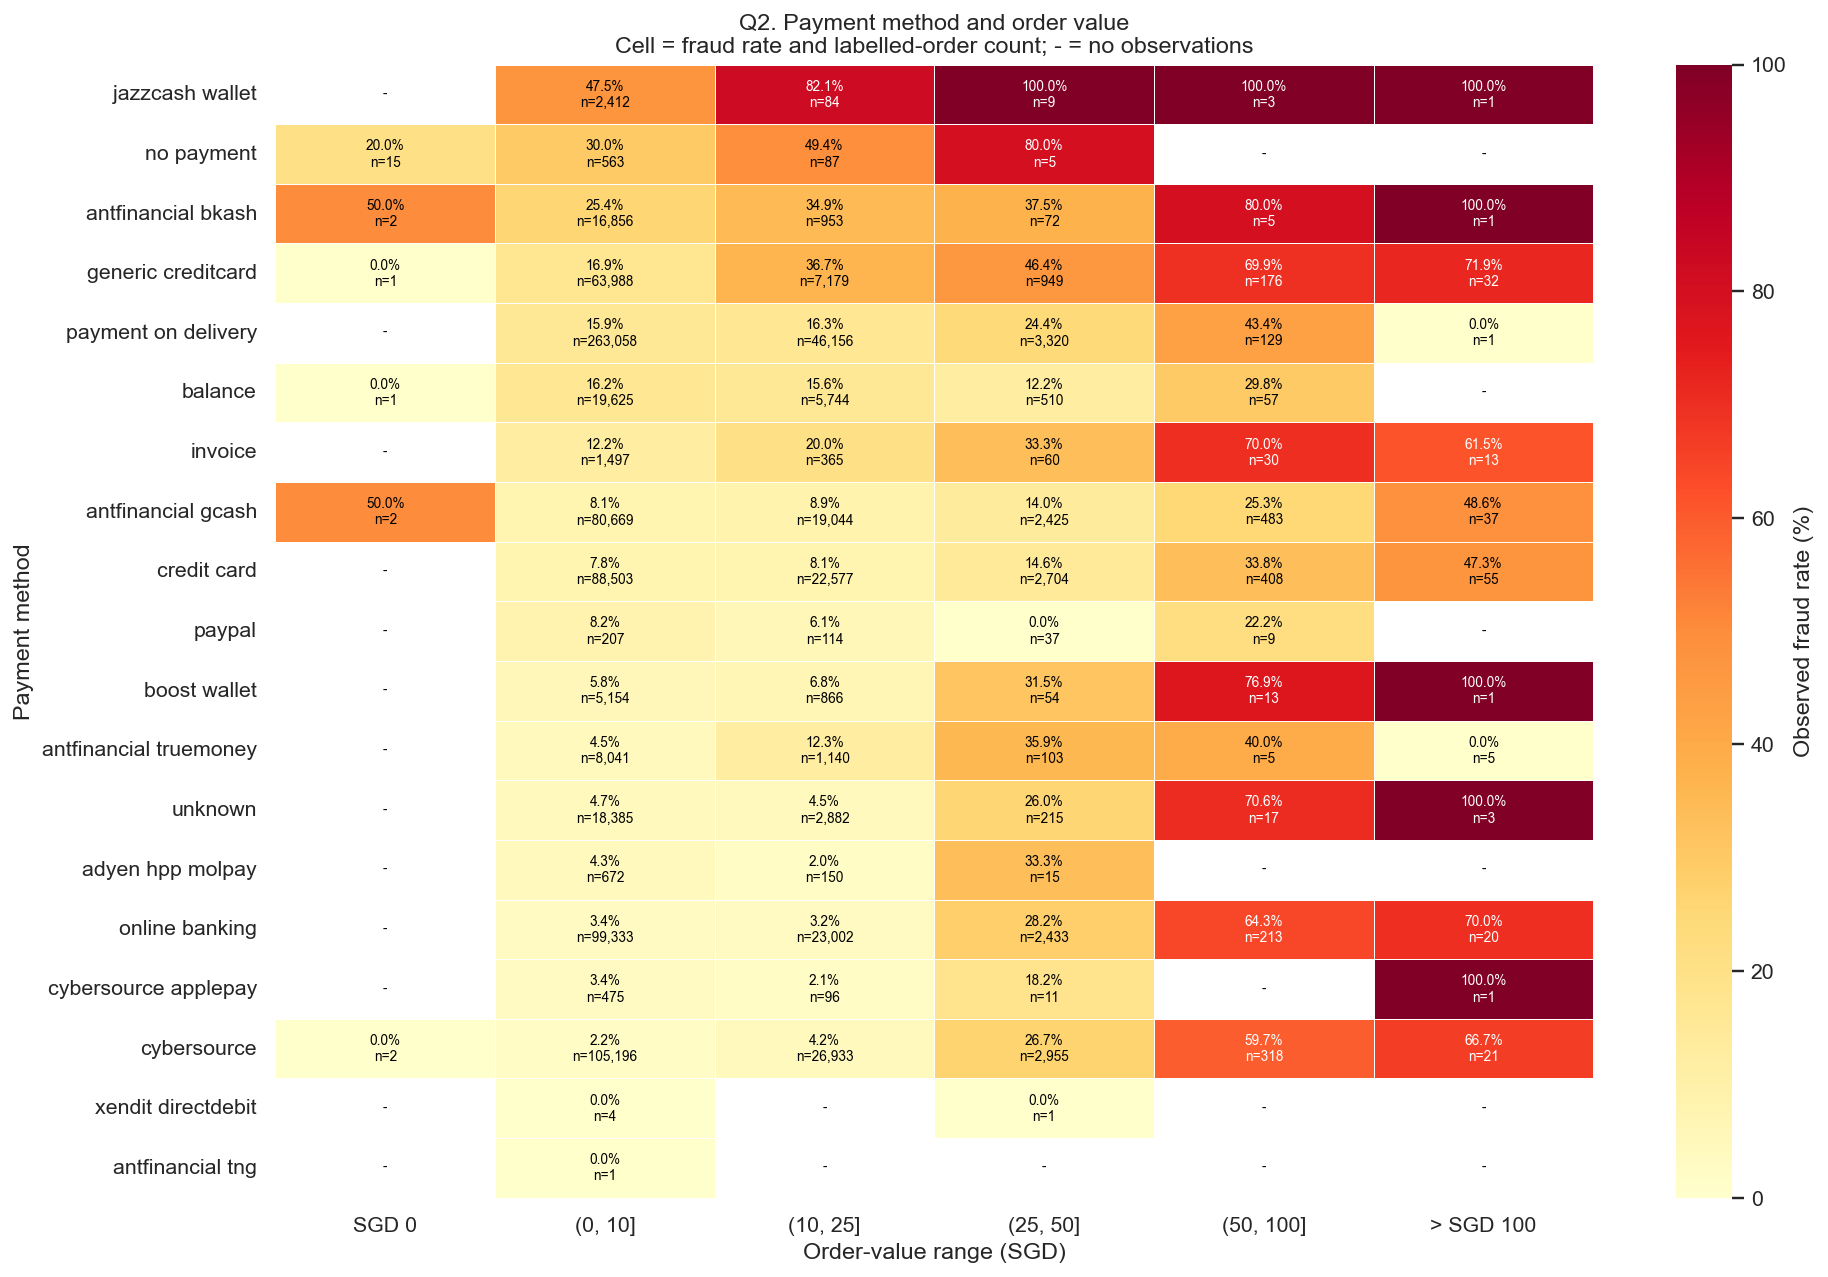

In [10]:
display(Image(filename=str(output_dir / "q2_payment_value.png")))

### 7.3 Insights from the payment/value results
I highlight the supported group with the largest within-method lift, then
compare its actual rate, counts and method baseline. A large lift can partly
reflect a low baseline, so it must be interpreted alongside those quantities.

In [11]:
q2_text = result["summary"].split("## Q2.", 1)[1].split("## Q3.", 1)[0]
q2_body = q2_text.split("\n", 1)[1].strip()
q2_insights, q2_decision = q2_body.split("Decision:", 1)
display(Markdown(q2_insights.strip() or
    "No supported group has a defined within-method lift for highlighting."))

eligible_q2 = q2[q2["highlight_support"] & q2["within_method_lift"].notna()].sort_values(
    ["within_method_lift", "orders", "payment_method", "value_band"],
    ascending=[False, False, True, True]
)
if not eligible_q2.empty:
    example = eligible_q2.iloc[0]
    display(Markdown(
        f"**Calculation check:** {example.fraud_rate_pct:.2f}% ÷ "
        f"{example.method_baseline_pct:.2f}% ≈ **{example.within_method_lift:.2f}×** "
        "the same method's baseline. Displayed rates are rounded; calculations "
        "use the unrounded values."
    ))

The largest within-method lift among supported groups is **cybersource, (50, 100]**: 59.75% fraud (190/318), 18.19 times that method's 3.29% baseline.

**Calculation check:** 59.75% ÷ 3.29% ≈ **18.19×** the same method's baseline. Displayed rates are rounded; calculations use the unrounded values.

### 7.4 Investigation decision
I examine payment method and value together, rather than assuming that all
expensive orders or all orders using a particular provider have equal risk.

In [12]:
display(Markdown(q2_decision.strip()))

investigate the supported payment/value combinations with elevated rates and meaningful fraud counts; a larger order is not automatically riskier. Consult country-specific results and intervals.

## 8. Q3 - Delivery Versus Pickup Within Payment Methods
**Question:** How do fraud rates differ between delivery and pickup orders across payment methods?

### 8.1 Method and calculations
I calculate delivery and pickup rates separately for each payment method, then
pair them using the payment-method identifier.

**Signed gap (percentage points) = Delivery fraud rate − Pickup fraud rate.**

- A positive gap means the delivery point estimate is higher.
- A negative gap means the pickup point estimate is higher.
- If one group is absent, the comparison is undefined; it is not zero risk.

I highlight the largest absolute gap only when **both** groups contain at least
100 labelled orders. This support rule does not establish statistical significance.
Percentage-point gaps are differences between percentages, not relative percentage changes.

In [13]:
q3_gaps = tables["q3_delivery_pickup_gaps"]
gap_columns = [
    "payment_method", "orders_delivery", "orders_pickup",
    "fraud_rate_pct_delivery", "fraud_rate_pct_pickup",
    "delivery_minus_pickup_pp", "both_groups_supported"
]
display(q3_gaps[gap_columns])

,payment_method,orders_delivery,orders_pickup,fraud_rate_pct_delivery,fraud_rate_pct_pickup,delivery_minus_pickup_pp,both_groups_supported
0,adyen hpp molpay,835,2,4.43,0.00,4.43,False
1,antfinancial bkash,16140,1749,22.48,58.26,-35.78,True
2,antfinancial gcash,101197,1463,8.38,16.88,-8.50,True
3,antfinancial tng,1,0,0.00,NaN,NaN,False
4,antfinancial truemoney,9227,67,5.77,7.46,-1.70,False
5,balance,25315,622,15.70,28.78,-13.08,True
6,boost wallet,5908,180,6.09,14.44,-8.35,True
7,credit card,111439,2808,7.48,34.97,-27.49,True
8,cybersource,134088,1337,3.27,4.86,-1.59,True
9,cybersource applepay,569,14,3.16,21.43,-18.27,False


### 8.2 Visual comparison
The chart compares delivery and pickup point estimates with 95% Wilson intervals
on the same scale. An absent group has no point. I use the table's counts to
judge support; the intervals are descriptive and are not a formal test of each gap.

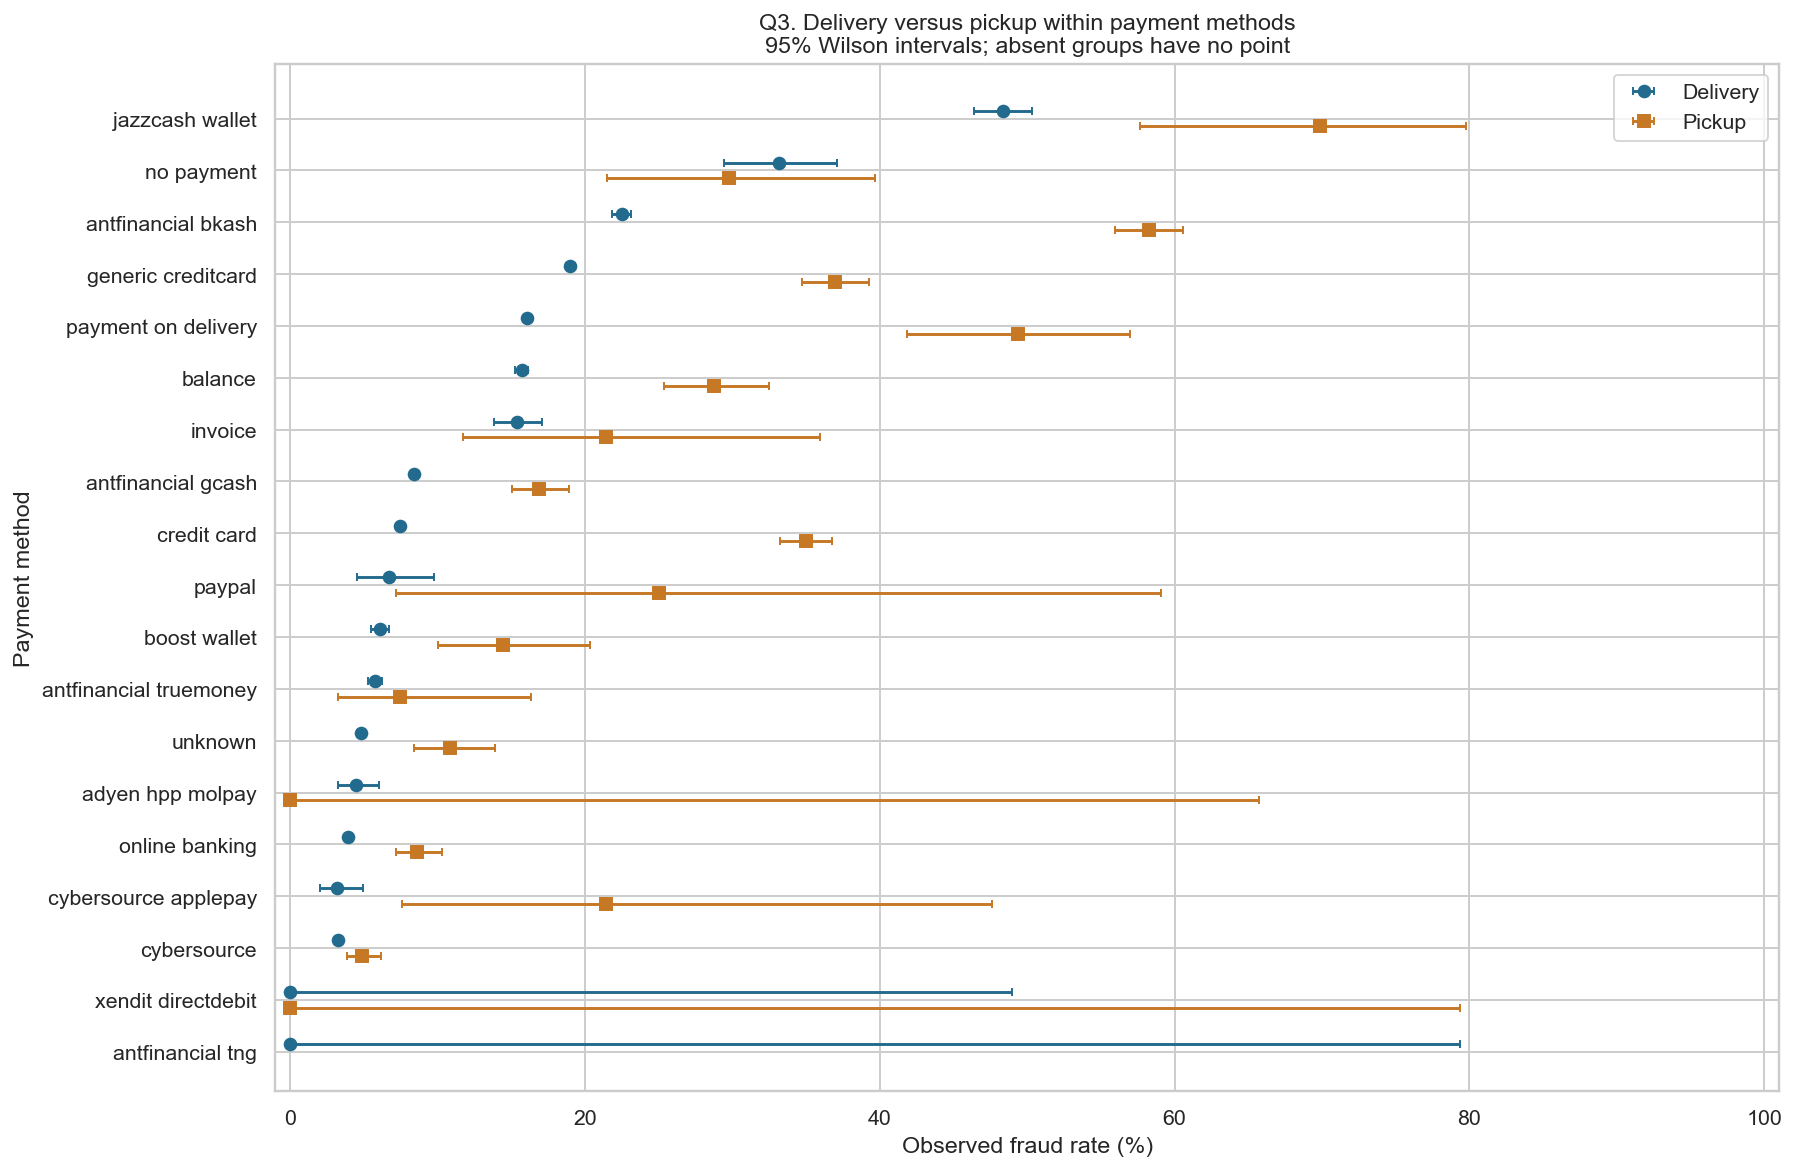

In [14]:
display(Image(filename=str(output_dir / "q3_payment_collection.png")))

### 8.3 Insights from the collection-type results
The interpretation below reports both collection rates and their sample sizes,
so the direction and scale of the comparison remain explicit.

In [15]:
q3_text = result["summary"].split("## Q3.", 1)[1].split("## Definitions", 1)[0]
q3_body = q3_text.split("\n", 1)[1].strip()
q3_insights, q3_decision = q3_body.split("Decision:", 1)
display(Markdown(q3_insights.strip()))

comparable_q3 = q3_gaps[q3_gaps["both_groups_supported"]].copy()
comparable_q3["absolute_gap"] = comparable_q3["delivery_minus_pickup_pp"].abs()
comparable_q3 = comparable_q3.sort_values(
    ["absolute_gap", "payment_method"], ascending=[False, True]
)
if not comparable_q3.empty:
    example = comparable_q3.iloc[0]
    display(Markdown(
        f"**Calculation check — {example.payment_method}:** "
        f"{example.fraud_rate_pct_delivery:.2f}% − {example.fraud_rate_pct_pickup:.2f}% "
        f"= **{example.delivery_minus_pickup_pp:+.2f} percentage points** "
        "using unrounded rates."
    ))

The largest absolute gap with both groups supported is **antfinancial bkash**: Delivery 22.48% (n=16,140) versus Pickup 58.26% (n=1,749). Pickup has the higher point estimate; signed Delivery-minus-Pickup gap -35.78 percentage points.

**Calculation check — antfinancial bkash:** 22.48% − 58.26% = **-35.78 percentage points** using unrounded rates.

### 8.4 Investigation decision
Collection type is interpreted within the payment method, with country-specific
checking before any policy change. The comparison alone does not explain why
a difference occurs.

In [16]:
display(Markdown(q3_decision.strip()))

review payment/collection combinations rather than treating all delivery or pickup orders as equally risky. A missing comparison group means insufficient evidence, not zero risk.

## 9. Country Detail and Interpretation Limits
Payment methods are not uniformly available across countries, so a pooled
association can partly reflect country composition. The tables below retain
that detail for the payment-method and collection comparisons. Full country/value
and country/collection tables are also saved in the execution folder.

**Limits I consider when using these findings:**

- Results describe the available labelled orders and may not represent all transactions.
- Labels can change, and later ETL batches can alter counts and rates.
- Multiple orders can belong to the same customer, so observations may not be independent.
- Wilson intervals use a binomial approximation; they do not establish future performance.
- Missing groups and tiny samples cannot establish that a segment is safe.
- These associations support investigation priorities, rather than proving causation.

In [17]:
display(tables["q1_country_payment"][[
    "country_code", "payment_method", "orders", "frauds", "fraud_rate_pct"
]])
display(tables["q3_country_delivery_pickup_gaps"][[
    "country_code", "payment_method", "orders_delivery", "orders_pickup",
    "delivery_minus_pickup_pp", "both_groups_supported"
]])

,country_code,payment_method,orders,frauds,fraud_rate_pct
0,BD,antfinancial bkash,17889,4648,25.98
1,BD,balance,465,127,27.31
2,BD,credit card,9808,2467,25.15
3,BD,invoice,4,2,50.00
4,BD,no payment,2,2,100.00
5,BD,payment on delivery,31396,10190,32.46
6,MY,adyen hpp molpay,837,37,4.42
7,MY,antfinancial tng,1,0,0.00
8,MY,boost wallet,6088,386,6.34
9,MY,credit card,31139,1287,4.13


,country_code,payment_method,orders_delivery,orders_pickup,delivery_minus_pickup_pp,both_groups_supported
0,BD,antfinancial bkash,16140,1749,-35.78,True
1,BD,balance,418,47,-42.99,False
2,BD,credit card,8705,1103,-47.86,True
3,BD,invoice,4,0,NaN,False
4,BD,no payment,1,1,0.00,False
5,BD,payment on delivery,31356,40,-7.55,False
6,MY,adyen hpp molpay,835,2,4.43,False
7,MY,antfinancial tng,1,0,NaN,False
8,MY,boost wallet,5908,180,-8.35,True
9,MY,credit card,30741,398,-2.18,True


## 10. Final Conclusion and Investigation Priorities
The questions address different decisions: Q1 identifies payment-method
concentration and scale, Q2 identifies value ranges within a method, and Q3
checks whether collection type adds useful descriptive detail.

I combine these perspectives below. The rows are complementary review leads,
not a validated ranking or a set of automatic transaction-blocking rules.
The examples and numbers are derived from this execution's results.

In [18]:
priorities = []
if overview["frauds"]:
    volume = q1.sort_values(
        ["frauds", "orders", "payment_method"], ascending=[False, False, True]
    ).iloc[0]
    priorities.append({
        "perspective": "Scale of observed fraud",
        "focus": volume.payment_method,
        "evidence": f"{int(volume.frauds):,} fraud labels; {volume.share_fraud_pct:.2f}% of observed fraud",
        "investigation action": "Consider this fraud volume when planning review capacity; inspect the country mix.",
    })
if not supported_q1.empty:
    top = supported_q1.iloc[0]
    priorities.append({
        "perspective": "Highest supported payment-method rate",
        "focus": top.payment_method,
        "evidence": f"{top.fraud_rate_pct:.2f}% fraud; {int(top.frauds):,}/{int(top.orders):,} labelled orders",
        "investigation action": "Examine the high-rate segment and its uncertainty before changing monitoring controls.",
    })
if not eligible_q2.empty and eligible_q2.iloc[0].within_method_lift > 1:
    top = eligible_q2.iloc[0]
    priorities.append({
        "perspective": "Payment and order value",
        "focus": f"{top.payment_method}: {top.value_band} SGD",
        "evidence": f"{top.fraud_rate_pct:.2f}% fraud; {top.within_method_lift:.2f}x its method baseline; n={int(top.orders):,}",
        "investigation action": "Review this combination; avoid extending its rate to every order using the provider.",
    })
if not comparable_q3.empty and comparable_q3.iloc[0].absolute_gap > 0:
    top = comparable_q3.iloc[0]
    higher_mode = "Delivery" if top.delivery_minus_pickup_pp > 0 else "Pickup"
    priorities.append({
        "perspective": "Payment and collection type",
        "focus": f"{top.payment_method}: {higher_mode}",
        "evidence": f"Delivery {top.fraud_rate_pct_delivery:.2f}% vs Pickup {top.fraud_rate_pct_pickup:.2f}%; gap {top.delivery_minus_pickup_pp:+.2f} pp",
        "investigation action": "Inspect the higher-rate combination with country-specific counts and label coverage.",
    })
if priorities:
    display(pd.DataFrame(priorities))
else:
    display(Markdown("The current snapshot provides insufficient supported evidence for highlighted review leads."))
display(Markdown(
    "**My conclusion:** investigation priorities should consider the **observed rate, "
    "fraud volume, order value and collection context together**. A high-rate segment "
    "and a high-volume segment can require different responses. I would verify the "
    "country breakdown, sample support and label coverage before proposing changes "
    "to controls, then repeat the analysis when updated labelled data becomes available. "
    "These results support closer review; they do not justify automatically treating "
    "every order in a highlighted segment as fraudulent."
))

,perspective,focus,evidence,investigation action
0,Scale of observed fraud,payment on delivery,"50,274 fraud labels; 48.14% of observed fraud",Consider this fraud volume when planning revie...
1,Highest supported payment-method rate,jazzcash wallet,"48.90% fraud; 1,227/2,509 labelled orders",Examine the high-rate segment and its uncertai...
2,Payment and order value,"cybersource: (50, 100] SGD",59.75% fraud; 18.19x its method baseline; n=318,Review this combination; avoid extending its r...
3,Payment and collection type,antfinancial bkash: Pickup,Delivery 22.48% vs Pickup 58.26%; gap -35.78 pp,Inspect the higher-rate combination with count...


**My conclusion:** investigation priorities should consider the **observed rate, fraud volume, order value and collection context together**. A high-rate segment and a high-volume segment can require different responses. I would verify the country breakdown, sample support and label coverage before proposing changes to controls, then repeat the analysis when updated labelled data becomes available. These results support closer review; they do not justify automatically treating every order in a highlighted segment as fraudulent.

## 11. Reproduction, Outputs and Individual Submission

| Item | Location or command |
|---|---|
| SQL, calculations and figures | `src/analytics_payment_order_chu.py` |
| Explanatory notebook | `notebooks/payment_order_analytics_chu.ipynb` |
| Automated calculation, SQL and export checks | `tests/test_analytics_payment_order_chu.py` |
| Standalone execution | `.venv\Scripts\python.exe src/analytics_payment_order_chu.py` |
| Local tests | `.venv\Scripts\python.exe -m pytest tests/test_analytics_payment_order_chu.py -q` |

The analysis exports eight aggregate CSV tables, three figures, `summary.md` and
execution metadata. Each live execution creates a separate output folder. The tests
use isolated SQLite fixtures to check the composite join, denominators, value-band
boundaries, missing collection groups, updated reads, generated insights and exports.
They do not replace a live AWS RDS connectivity check.

For **individual template A1**, the three question sections provide the method,
results, visualisations, insights and investigation decisions. This notebook covers
the analytics; Prefect orchestration and its execution evidence belong to the
separate **A2** work.

In [19]:
print("Results retrieved at (UTC):", overview["retrieved_at"])
print("Saved output folder:", output_dir)
print(f"Recorded RDS read time: {overview['read_seconds']:.2f} seconds")
print(f"Recorded analysis and export time: {overview['duration_seconds']:.2f} seconds")
print("Exports:")
for path in sorted(output_dir.iterdir()):
    print(" -", path.name)

Results retrieved at (UTC): 2026-11-28T16:22:34.779031+00:00
Saved output folder: C:\Users\User\Desktop\AMLOPs\CA1\MLOps_CA1_group5\docs\evidence\task63_chu
Recorded RDS read time: 24.14 seconds
Recorded analysis and export time: 25.41 seconds
Exports:
 - metadata.json
 - q1_country_payment.csv
 - q1_payment_methods.csv
 - q1_payment_methods.png
 - q2_country_payment_value.csv
 - q2_payment_value.csv
 - q2_payment_value.png
 - q3_country_delivery_pickup_gaps.csv
 - q3_country_payment_collection.csv
 - q3_delivery_pickup_gaps.csv
 - q3_payment_collection.csv
 - q3_payment_collection.png
 - summary.md
 - verification.json
